<a href="https://colab.research.google.com/github/shaikriyaz007/Real-Time-Delivery-Fleet-Monitoring-Using-Power-BI/blob/main/Real-Time%20Delivery%20Fleet%20monitoring%20using%20powerBI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from datetime import datetime, timedelta

np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
drivers = [f"D{i:02d}" for i in range(1, 16)]

zones = ["Northwest", "Northeast", "Southwest", "Southeast"]

statuses = ["Picked up", "In transit", "Delayed", "Delivered"]

data = []

start_time = datetime(2026, 11, 2, 9, 0, 0)

for minute in range(480):

    timestamp = start_time + timedelta(minutes=minute)

    for driver in drivers:

        speed = np.random.randint(20, 71)

        eta = np.random.randint(5, 51)

        zone = np.random.choice(zones)

        status = np.random.choice(
            statuses,
            p=[0.15, 0.50, 0.20, 0.15]
        )

        traffic = np.random.choice(
            ["Normal", "Heavy", "Low"],
            p=[0.65, 0.25, 0.10]
        )

        if traffic == "Heavy":
            speed = max(10, speed - 15)
            eta += 10

        elif traffic == "Low":
            speed += 5

        late_by = max(0, eta - 20) if status == "Delayed" else 0

        active = 0 if status == "Delivered" else 1

        delayed = 1 if status == "Delayed" else 0

        on_time = 1 if status == "Delivered" and eta <= 20 else 0

        distance = round(np.random.uniform(1, 30), 2)

        data.append([
            timestamp,
            driver,
            zone,
            status,
            speed,
            eta,
            traffic,
            late_by,
            active,
            delayed,
            on_time,
            distance
        ])

columns = [
    "Timestamp",
    "Driver_ID",
    "Zone",
    "Status",
    "Speed_kmph",
    "ETA_minutes",
    "Traffic",
    "Late_by_minutes",
    "Active_Flag",
    "Delayed_Flag",
    "On_Time_Flag",
    "Distance_km"
]

df = pd.DataFrame(data, columns=columns)

print("Dataset generated successfully!")
df.head()

Dataset generated successfully!


,Timestamp,Driver_ID,Zone,Status,Speed_kmph,ETA_minutes,Traffic,Late_by_minutes,Active_Flag,Delayed_Flag,On_Time_Flag,Distance_km
0,2026-11-02 09:00:00,D01,Southwest,In transit,11,36,Heavy,0,1,0,0,7.38
1,2026-11-02 09:00:00,D02,Southeast,In transit,52,35,Normal,0,1,0,0,8.67
2,2026-11-02 09:00:00,D03,Northwest,In transit,30,27,Heavy,0,1,0,0,29.63
3,2026-11-02 09:00:00,D04,Southeast,Delayed,55,27,Normal,7,1,1,0,1.87
4,2026-11-02 09:00:00,D05,Southwest,In transit,66,48,Normal,0,1,0,0,27.43


In [ ]:
print("EXPECTED DATASET SIZE")
print("----------------------------")

print("Total Drivers:", df["Driver_ID"].nunique())

print("Duration: 8 Hours")

print("Records per Driver:", df.groupby("Driver_ID").size().iloc[0])

print("Total Records:", len(df))

print("----------------------------")

EXPECTED DATASET SIZE
----------------------------
Total Drivers: 15
Duration: 8 Hours
Records per Driver: 480
Total Records: 7200
----------------------------


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (7200, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7200 entries, 0 to 7199
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Timestamp        7200 non-null   datetime64[ns]
 1   Driver_ID        7200 non-null   object        
 2   Zone             7200 non-null   object        
 3   Status           7200 non-null   object        
 4   Speed_kmph       7200 non-null   int64         
 5   ETA_minutes      7200 non-null   int64         
 6   Traffic          7200 non-null   object        
 7   Late_by_minutes  7200 non-null   int64         
 8   Active_Flag      7200 non-null   int64         
 9   Delayed_Flag     7200 non-null   int64         
 10  On_Time_Flag     7200 non-null   int64         
 11  Distance_km      7200 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(6), object(4)
memory usage: 675.1+ KB

Missing Values:
Tim

,Timestamp,Speed_kmph,ETA_minutes,Late_by_minutes,Active_Flag,Delayed_Flag,On_Time_Flag,Distance_km
count,7200,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000
mean,2026-11-02 12:59:30,41.970417,29.875417,2.455556,0.857917,0.203472,0.037222,15.420144
min,2026-11-02 09:00:00,10.000000,5.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2026-11-02 10:59:45,29.000000,18.750000,0.000000,1.000000,0.000000,0.000000,8.265000
50%,2026-11-02 12:59:30,42.000000,30.000000,0.000000,1.000000,0.000000,0.000000,15.380000
75%,2026-11-02 14:59:15,55.000000,41.000000,0.000000,1.000000,0.000000,0.000000,22.540000
max,2026-11-02 16:59:00,75.000000,60.000000,40.000000,1.000000,1.000000,1.000000,30.000000
std,NaN,16.158485,13.776092,7.141397,0.349160,0.402609,0.189319,8.362844


In [ ]:
print("EXPECTED DATASET SIZE")
print("----------------------------")

print("Total Drivers:", df["Driver_ID"].nunique())

print("Duration: 8 Hours")

print("Records per Driver:", df.groupby("Driver_ID").size().iloc[0])

print("Total Records:", len(df))

print("----------------------------")

EXPECTED DATASET SIZE
----------------------------
Total Drivers: 15
Duration: 8 Hours
Records per Driver: 480
Total Records: 7200
----------------------------


In [ ]:
active_deliveries = df["Active_Flag"].sum()

delayed_deliveries = df["Delayed_Flag"].sum()

average_speed = df["Speed_kmph"].mean()

average_eta = df["ETA_minutes"].mean()

on_time_rate = df["On_Time_Flag"].mean() * 100

print("DELIVERY FLEET MONITORING DASHBOARD")
print("-----------------------------------")

print("Active Deliveries:", active_deliveries)

print("Delayed Deliveries:", delayed_deliveries)

print("Average Speed:", round(average_speed, 2), "km/h")

print("Average ETA:", round(average_eta, 2), "minutes")

print("On-Time Rate:", round(on_time_rate, 2), "%")

DELIVERY FLEET MONITORING DASHBOARD
-----------------------------------
Active Deliveries: 6177
Delayed Deliveries: 1465
Average Speed: 41.97 km/h
Average ETA: 29.88 minutes
On-Time Rate: 3.72 %


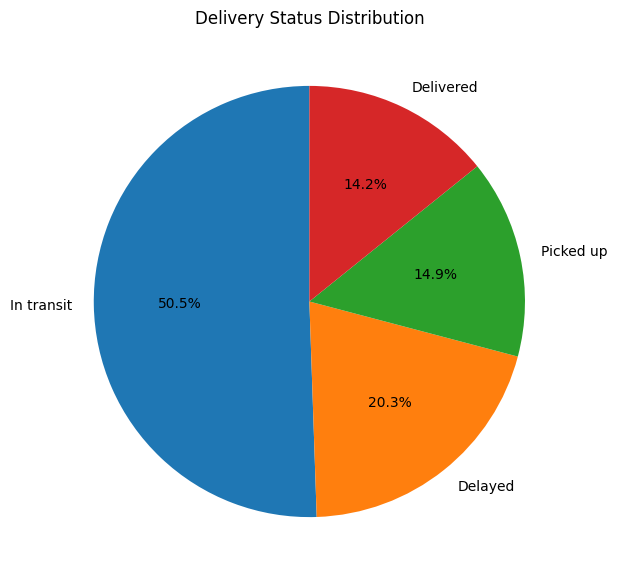

In [ ]:
status_data = df["Status"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    status_data,
    labels=status_data.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Delivery Status Distribution")

plt.show()

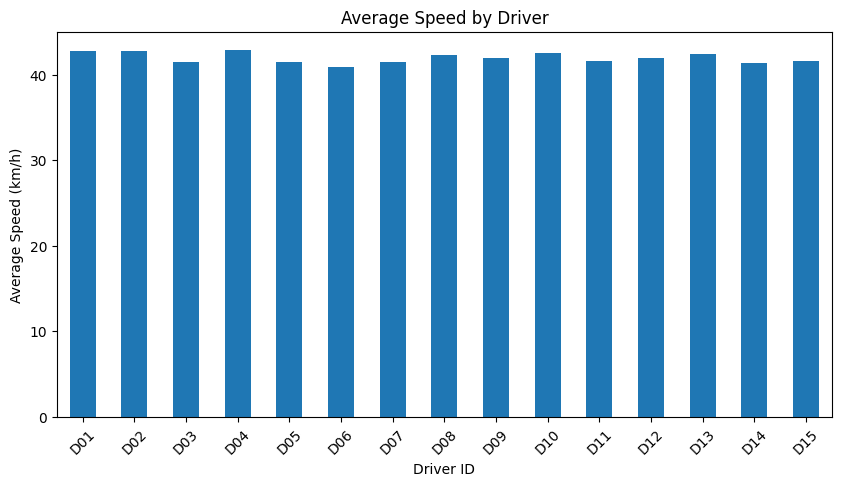

In [ ]:
driver_speed = df.groupby("Driver_ID")["Speed_kmph"].mean()

plt.figure(figsize=(10, 5))

driver_speed.plot(kind="bar")

plt.title("Average Speed by Driver")
plt.xlabel("Driver ID")
plt.ylabel("Average Speed (km/h)")

plt.xticks(rotation=45)
plt.show()

Zone
Northeast    357
Northwest    374
Southeast    349
Southwest    385
dtype: int64


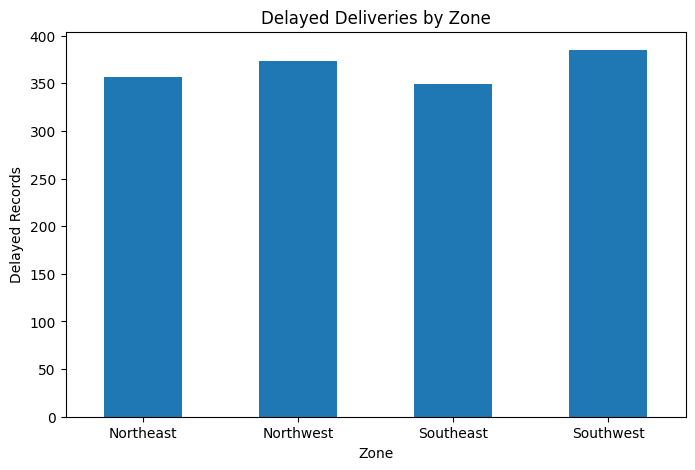

In [ ]:
delayed_data = df[df["Status"] == "Delayed"]

delayed_by_zone = delayed_data.groupby("Zone").size()

print(delayed_by_zone)

plt.figure(figsize=(8, 5))

delayed_by_zone.plot(kind="bar")

plt.title("Delayed Deliveries by Zone")
plt.xlabel("Zone")
plt.ylabel("Delayed Records")

plt.xticks(rotation=0)
plt.show()

In [ ]:
df.to_csv("Delivery_Fleet_Data.csv", index=False)

print("CSV file created successfully!")

files.download("Delivery_Fleet_Data.csv")

CSV file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
if traffic == "Heavy":
    speed = max(10, speed - 15)
    eta += 10

In [ ]:
active = 0 if status == "Delivered" else 1

In [ ]:
delayed = 1 if status == "Delayed" else 0

In [ ]:
on_time = 1 if status == "Delivered" and eta <= 20 else 0